## American Company Bankruptcy Prediction

Bankruptcy prediction is a data science and business analytics problem that involves using a company's financial information to predict whether it is at risk of bankruptcy or financial failure.

## 1.Business Understanding

The objective of this project is to develop a machine learning solution for predicting corporate bankruptcy using historical financial data. Bankruptcy can result in significant financial losses for lenders, investors, suppliers, employees, and other stakeholders. Identifying companies at risk of financial failure early can help organizations improve credit risk assessment, make informed investment decisions, and implement preventive financial measures.

## 1.1 Objective

  1.Identify financial indicators associated with bankruptcy.



  2.Analyze differences between bankrupt and financially healthy companies.



  3.Determine which financial variables are most useful for predicting bankruptcy.



  4.Build and evaluate a classification model.



  5.Help banks, investors, and business managers make better financial decisions.



  6.Reduce potential losses resulting from lending to financially distressed companies

## 1.2 Key business questions
- How many companies are labelled alive and how many are labelled failed?
- Are the two groups different in their financial indicators?
- Which financial variables are most useful for distinguishing the groups?
- Which machine learning model performs best?
- How many failed companies does the model correctly identify?
- What are the business implications of incorrectly classifying a failed company as alive?

## 1.3 Stakeholders
| Stakeholder | Business Need|
|---|---|
|Banks and lenders|	Assess the risk of lending to companies.|
|Investors|	Identify financially risky companies before investing.|
|Company management|	Detect financial problems and take corrective action.|
|Credit risk analysts|	Improve the assessment of corporate creditworthiness.|
|Regulators|	Monitor financial stability and potential corporate failures.|
|Suppliers|	Evaluate whether customers are likely to pay their debts.|

## 1.4 Assumptions

* **Data are annual and only for public companies**, so the model cannot be applied directly to private or very small firms.
* **No sector, no cash-flow statement, no interest expense, no credit ratings.** Some well-known predictors cannot be built.
* **Failure label:** a company marked `failed` is assumed to have filed for bankruptcy shortly after its last year of financial data 
* **Right-censoring:** a company marked `alive` is only known to be alive through its last reported year.
* **Time dependence:** economic cycles change failure rates, so the model must be tested on *later* years than it was trained on.
* **Ethical risk:** false positives can hurt healthy firms, so the output must always be reviewed by a person.

## 2. Data Understanding

## 2.1 Data Source And Description

The dataset was sourced from [kaggle](https://www.kaggle.com/datasets/utkarshx27/american-companies-bankruptcy-prediction-dataset/data?select=american_bankruptcy.csv)

The dataset contains **annual financial statement data for US public companies, 1999-2018**. Each row is one company in one fiscal year. A company is labelled `failed` if it went bankrupt  and `alive` otherwise. The label belongs to the **company**, not the year.

| Column | Meaning |
|---|---|
| `company_name` | Anonymised company ID (C_1, C_2, ...) |
| `status_label` | `alive` or `failed` (company-level label) |
| `year` | Fiscal year of the financial statements |
| `X1` Current assets | Assets expected to be sold or used in normal operations within the next year |
| `X2` Cost of goods sold | Direct cost of the products sold |
| `X3` Depreciation & amortization | Loss of value of tangible (depreciation) and intangible (amortization) assets over time |
| `X4` EBITDA | Earnings before interest, taxes, depreciation and amortization |
| `X5` Inventory | Items and raw materials used in production or held for sale |
| `X6` Net income | Profit after all expenses and costs |
| `X7` Total receivables | Money owed by customers for goods or services already delivered |
| `X8` Market value | Market capitalisation (companies are publicly traded) |
| `X9` Net sales | Gross sales minus returns, allowances and discounts |
| `X10` Total assets | Everything of value the company owns |
| `X11` Total long-term debt | Loans and liabilities not due within one year |
| `X12` EBIT | Earnings before interest and taxes |
| `X13` Gross profit | Profit after the direct costs of making and selling products or services |
| `X14` Total current liabilities | Obligations due within the year (payables, accrued liabilities, taxes, etc.) |
| `X15` Retained earnings | Cumulative profit kept in the business after costs, taxes and dividends |
| `X16` Total revenue | Income from all sales before expenses (may include interest and dividends) |
| `X17` Total liabilities | All debts and obligations owed to outside parties |
| `X18` Total operating expenses | Expenses from normal business operations |

> The data dictionary does not state the currency unit. These datasets are normally expressed in millions of US dollars, but this does not affect the analysis because the models use scale-free ratios.




## 2.2 importing libraries and loading Dataset



In [38]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 140)
RANDOM_STATE = 42

In [39]:
#Loading dataset
pd.set_option("display.max_columns", None)
df = pd.read_csv(r"C:\Users\DELL\Downloads\american_bankruptcy.csv.zip")
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (78682, 21)


,company_name,status_label,year,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,372.752,"1,024.333",740.998,180.447,70.658,191.226,163.816,201.026,"1,024.333",401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,377.118,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,364.593,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,143.329,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,308.907,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467


In [40]:
#Rename variable names for easy understanding
df = df.rename(
    columns={
        "X1": "current_assets",
        "X2": "cost_of_goods_sold",
        "X3": "depriciation",
        "X4": "ebitda",
        "X5": "operating_income",
        "X6": "net_income",
        "X7": "total_receivables",
        "X8": "market_value",
        "X9": "net_sales",
        "X10": "total_assets",
        "X11": "long_term_debt",
        "X12": "ebit",
        "X13": "gross_profit",
        "X14": "current_liabilities",
        "X15": "retained_earnings",
        "X16": "total_revenue",
        "X17": "total_debt",
        "X18": "operating_expenses",
    }
)

print(df)

      company_name status_label  year  current_assets  cost_of_goods_sold  depriciation  ebitda  operating_income  net_income  \
0              C_1        alive  1999         511.267             833.107        18.373  89.031           336.018      35.163   
1              C_1        alive  2000         485.856             713.811        18.577  64.367           320.590      18.531   
2              C_1        alive  2001         436.656             526.477        22.496  27.207           286.588     -58.939   
3              C_1        alive  2002         396.412             496.747        27.172  30.745           259.954     -12.410   
4              C_1        alive  2003         432.204             523.302        26.680  47.491           247.245       3.504   
...            ...          ...   ...             ...                 ...           ...     ...               ...         ...   
78677       C_8971        alive  2014         233.211              43.338        14.094  45.615  

## 2.3 Data Quality Assesment

In [41]:
#Find out the total number of rows and columns
print("Shape:", df.shape)

#display the data types of every column
print("\nData types:")
display(df.dtypes.to_frame("dtype"))

#Finds which columns have missing data, sorts them from highest to lowest, and shows the top 10 most "empty" columns.
print("\nMissing values ():")
display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing_count"))

#Checks if there are entirely identical rows repeated in the dataset
df.duplicated().sum()


Shape: (78682, 21)

Data types:


,dtype
company_name,str
status_label,str
year,int64
current_assets,float64
cost_of_goods_sold,float64
depriciation,float64
ebitda,float64
operating_income,float64
net_income,float64
total_receivables,float64



Missing values ():


,missing_count
company_name,0
status_label,0
year,0
current_assets,0
cost_of_goods_sold,0
depriciation,0
ebitda,0
operating_income,0
net_income,0
total_receivables,0


np.int64(0)

## 2.4 Data cleaning


- Standardize column names and trim text fields.
- Check that target labels are valid.
- Convert financial features to numeric values.
- Do not automatically remove outliers: unusually high or low financial values may be meaningful signals.
- Missing values are checked and handled inside model pipelines if any occur.
- Keep `company_name` for grouping and reporting, but exclude it from model predictors.

In [42]:
df.columns = df.columns.str.strip()
df["company_name"] = df["company_name"].astype(str).str.strip()
df["status_label"] = df["status_label"].astype(str).str.strip().str.lower()

feature_cols = ["current_assets", "cost_of_goods_sold", "depriciation", "ebitda", "operating_income", "net_income", "total_receivables", "market_value", "net_sales", "total_assets", "long_term_debt", "ebit", "gross_profit", "current_liabilities", "retained_earnings", "total_revenue", "total_debt", "operating_expenses"]

valid_labels = {"alive", "failed"}
print("Unexpected target labels:", sorted(set(df["status_label"].unique()) - valid_labels))
print("Rows duplicated after standardization:", int(df.duplicated().sum()))
display(df.describe(include="all").T.head(10))

Unexpected target labels: []
Rows duplicated after standardization: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
company_name,78682,8971,C_7,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status_label,78682,2,alive,73462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,"78,682.000",NaN,NaN,NaN,"2,007.506",5.743,"1,999.000","2,002.000","2,007.000","2,012.000","2,018.000"
current_assets,"78,682.000",NaN,NaN,NaN,880.362,"3,928.565",-7.760,18.924,100.450,431.527,"169,662.000"
cost_of_goods_sold,"78,682.000",NaN,NaN,NaN,"1,594.529","8,930.485",-366.645,17.038,103.661,634.548,"374,623.000"
depriciation,"78,682.000",NaN,NaN,NaN,121.234,652.377,0.000,1.192,7.929,47.972,"28,430.000"
ebitda,"78,682.000",NaN,NaN,NaN,376.759,"2,012.023","-21,913.000",-0.811,15.035,139.655,"81,730.000"
operating_income,"78,682.000",NaN,NaN,NaN,201.606,"1,060.766",0.000,0.000,7.023,74.747,"62,567.000"
net_income,"78,682.000",NaN,NaN,NaN,129.382,"1,265.532","-98,696.000",-7.416,1.616,40.144,"104,821.000"
total_receivables,"78,682.000",NaN,NaN,NaN,286.833,"1,335.979",-0.006,3.281,22.820,131.581,"65,812.000"


In [43]:
print([col for col in df.columns])


['company_name', 'status_label', 'year', 'current_assets', 'cost_of_goods_sold', 'depriciation', 'ebitda', 'operating_income', 'net_income', 'total_receivables', 'market_value', 'net_sales', 'total_assets', 'long_term_debt', 'ebit', 'gross_profit', 'current_liabilities', 'retained_earnings', 'total_revenue', 'total_debt', 'operating_expenses']


## 3. Exploratory Data Analysis (EDA)

## 3.1 Univariate Analysis: Class balance

Count how many rows belong to each category 



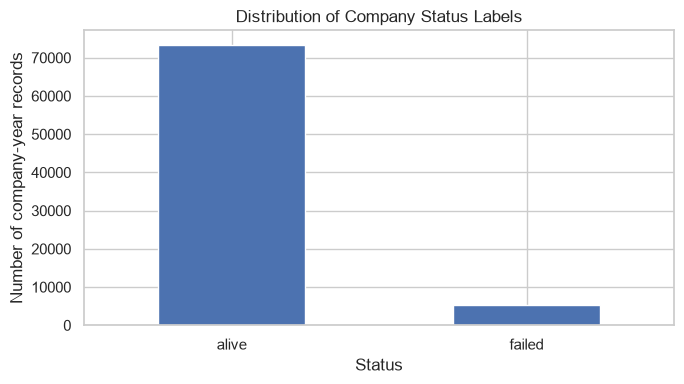

In [44]:
counts = df["status_label"].value_counts().reindex(["alive", "failed"])
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot(kind="bar", ax=ax)
ax.set_title("Distribution of Company Status Labels")
ax.set_xlabel("Status")
ax.set_ylabel("Number of company-year records")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 3.2 Variable Distribution



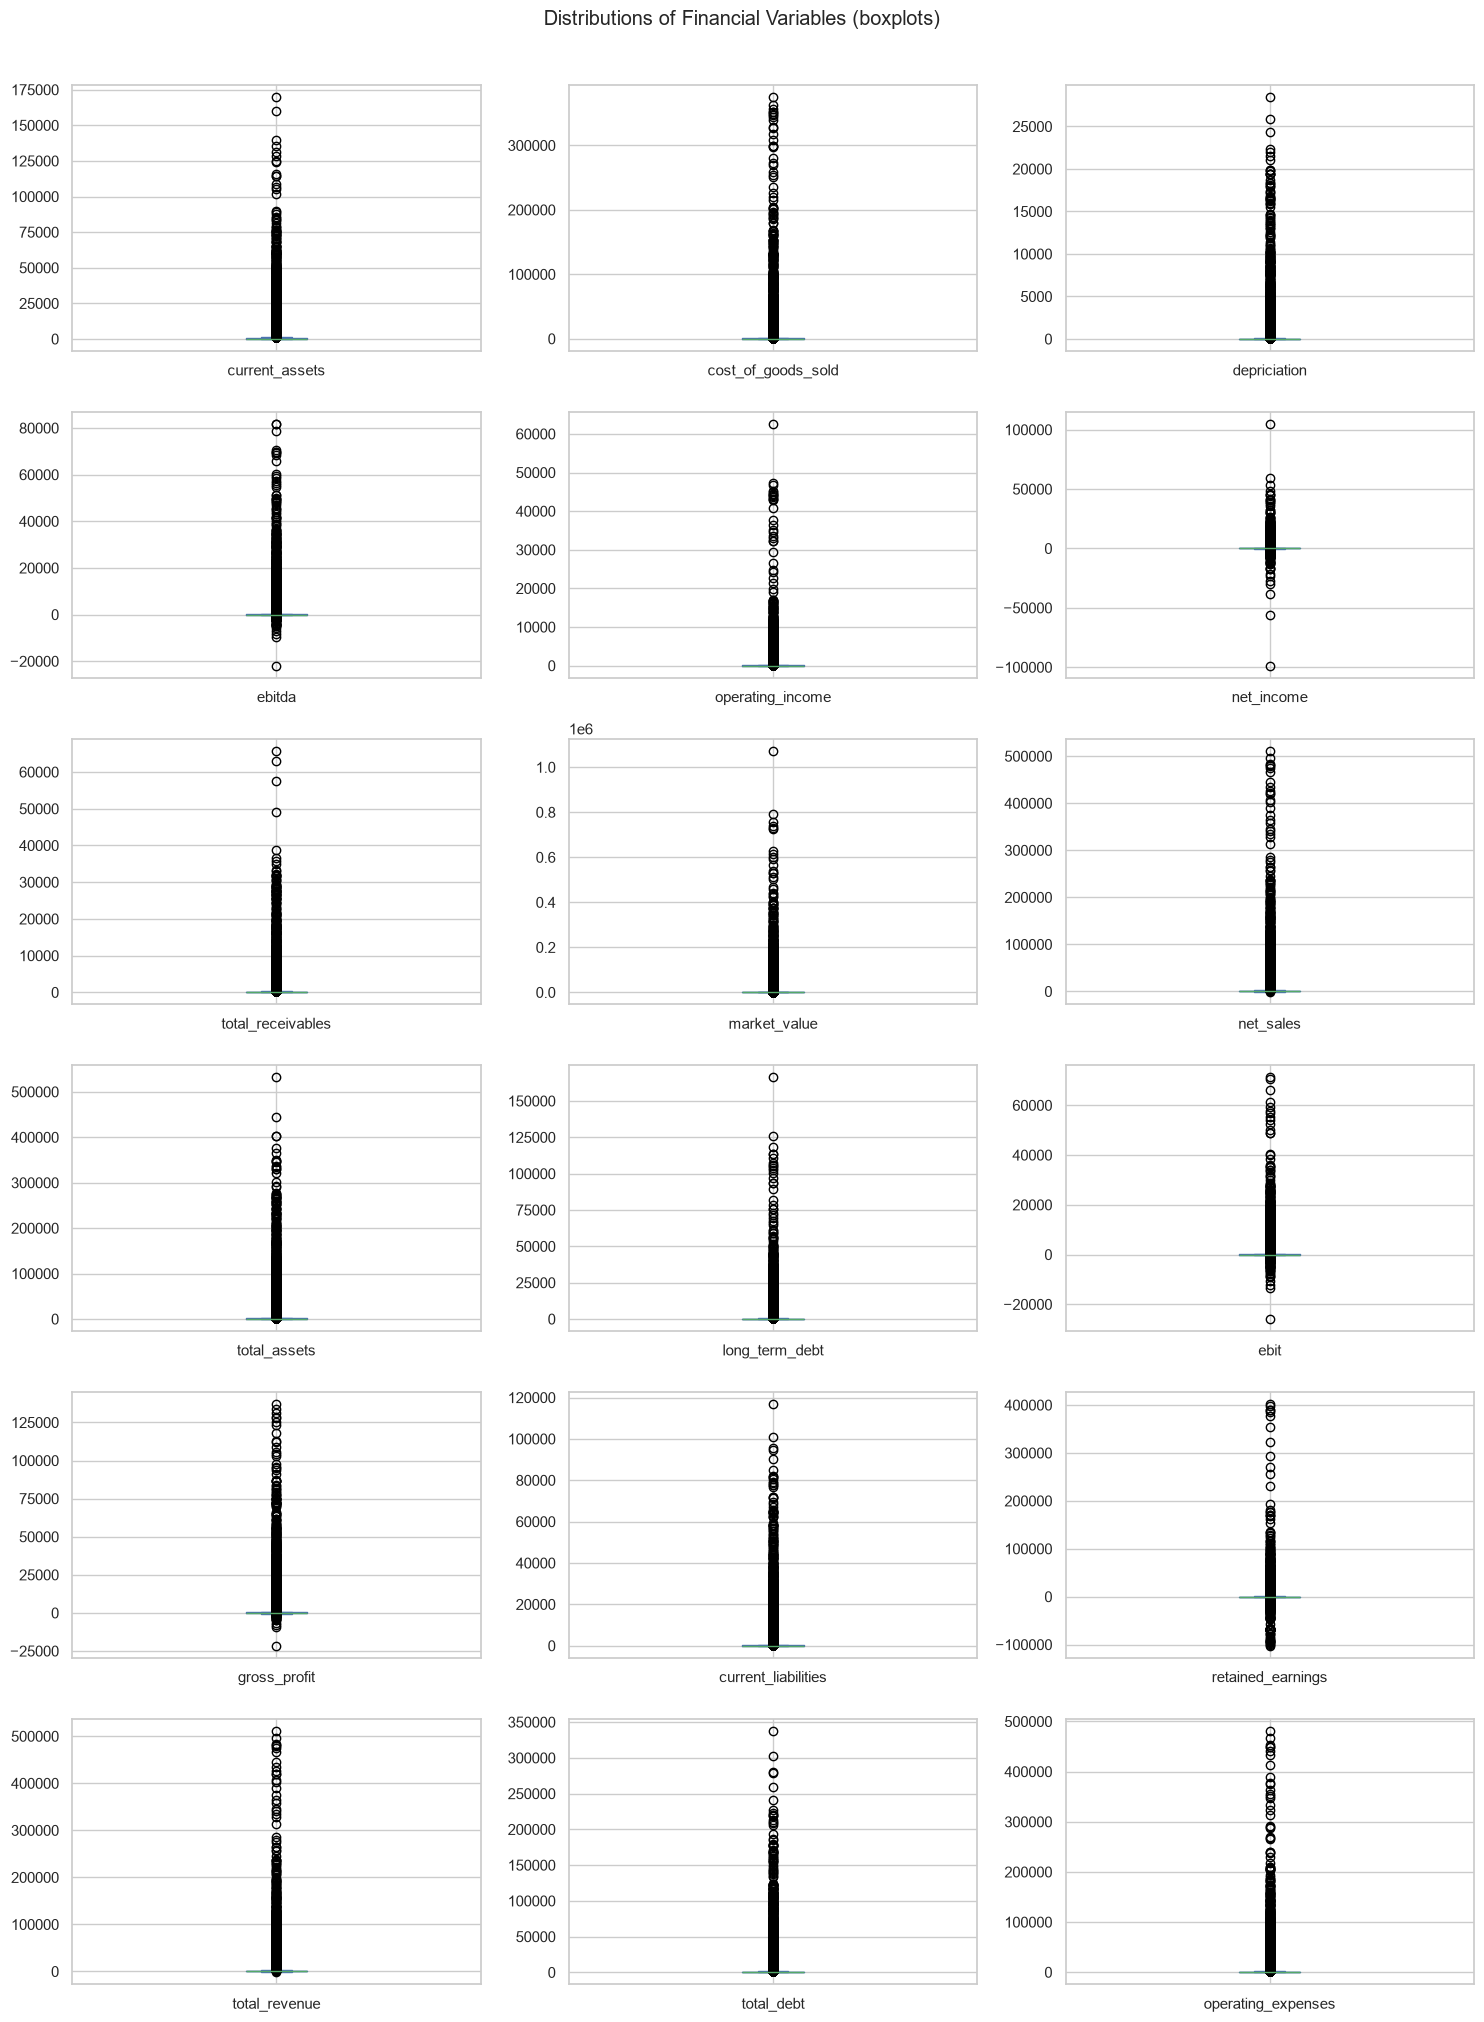

In [45]:
df[feature_cols].plot(kind="box", subplots=True, layout=(6, 3), figsize=(15, 20), sharex=False, sharey=False)
plt.suptitle("Distributions of Financial Variables (boxplots)", y=1.01)
plt.tight_layout()
plt.show()


## 3.3 Bivariate Analysis:Financial variables vs status



status_label,alive,failed
current_assets,102.917,75.871
cost_of_goods_sold,103.534,106.638
depriciation,7.935,7.847
ebitda,15.618,7.790
operating_income,7.117,6.171
net_income,2.072,-3.327
total_receivables,23.454,15.218
market_value,240.895,117.799
net_sales,187.070,180.834
total_assets,215.006,195.137


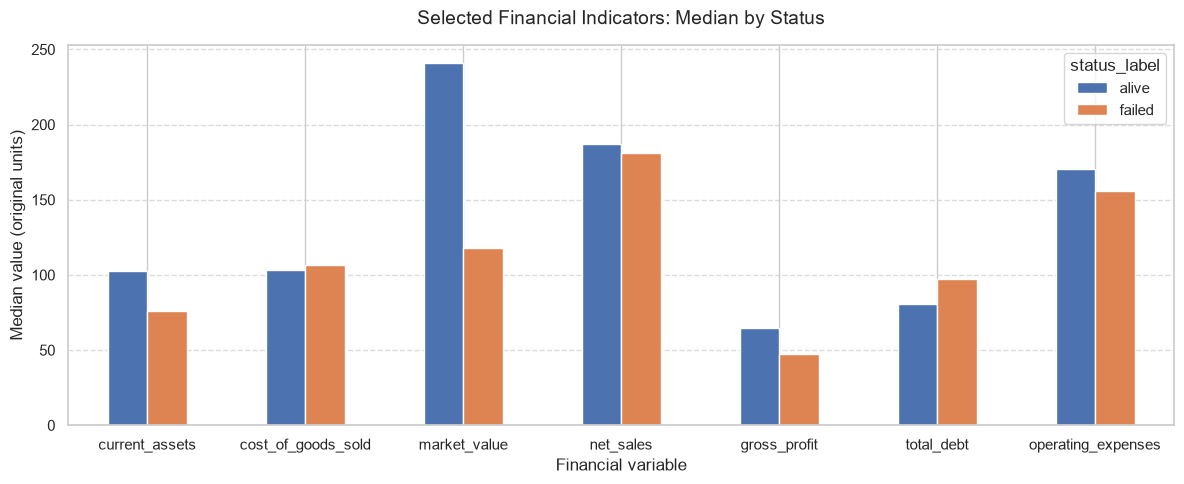

In [47]:


# 1. Calculate medians and transpose so features become rows
median_by_status = df.groupby("status_label")[feature_cols].median().T
display(median_by_status)

# 2. Filter for selected features and plot
selected = ["current_assets", "cost_of_goods_sold", "market_value", "net_sales", "gross_profit", "total_debt", "operating_expenses"]
median_by_status.loc[selected].plot(kind="bar", figsize=(12, 5))

# 3. Customize chart appearance
plt.title("Selected Financial Indicators: Median by Status", fontsize=14, pad=15)
plt.xlabel("Financial variable", fontsize=12)
plt.ylabel("Median value (original units)", fontsize=12)
plt.xticks(rotation=0)  
plt.grid(axis="y", linestyle="--", alpha=0.7)  # Added gridlines for readability
plt.tight_layout()
plt.show()


## 3.4 Status label by year


status_label  alive  failed  total_companies  failure_rate_pct
year                                                          
2003           4002     415             4417             9.396
2004           3944     404             4348             9.292
2005           3826     379             4205             9.013
2002           4237     414             4651             8.901
2006           3762     366             4128             8.866
2001           4483     414             4897             8.454
2007           3673     336             4009             8.381
2000           4822     404             5226             7.731
2008           3573     284             3857             7.363
1999           4928     380             5308             7.159
2009           3509     234             3743             6.252
2010           3407     218             3625             6.014
2011           3319     194             3513             5.522
2012           3303     182             3485           

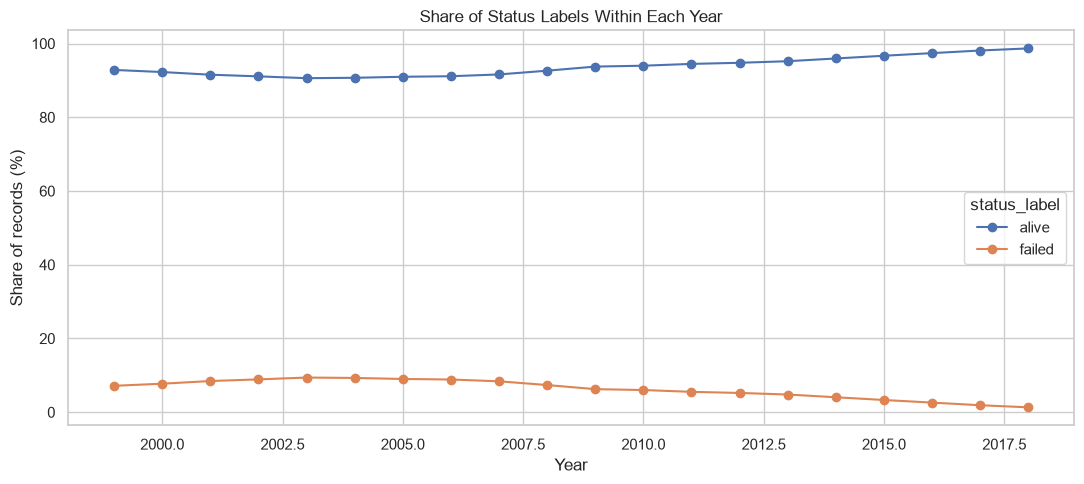

In [48]:


# Calculate absolute counts and percentages simultaneously
summary = pd.crosstab(df["year"], df["status_label"])
summary["total_companies"] = summary["alive"] + summary["failed"]
summary["failure_rate_pct"] = (summary["failed"] / summary["total_companies"]) * 100

# Sort by highest failure rate to isolate crisis periods immediately
deep_dive_df = summary.sort_values(by="failure_rate_pct", ascending=False)
print(deep_dive_df)
year_status = pd.crosstab(df["year"], df["status_label"], normalize="index") * 100
year_status.plot(kind="line", marker="o", figsize=(11, 5))
plt.title("Share of Status Labels Within Each Year")
plt.xlabel("Year")
plt.ylabel("Share of records (%)")
plt.tight_layout()
plt.show()


## 3.5 current_assets by company_status

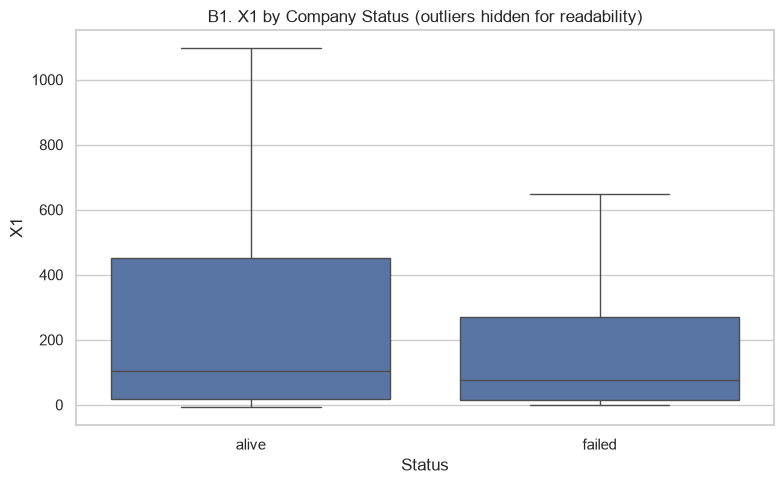

,count,mean,std,min,25%,50%,75%,max
status_label,,,,,,,,
alive,"73,462.000",914.543,"4,052.048",-7.760,19.235,102.917,450.042,"169,662.000"
failed,"5,220.000",399.339,"1,147.837",0.001,15.316,75.871,269.114,"16,548.000"


In [51]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="status_label", y="current_assets", showfliers=False)
plt.title("B1. X1 by Company Status (outliers hidden for readability)")
plt.xlabel("Status")
plt.ylabel("X1")
plt.tight_layout()
plt.show()

display(df.groupby("status_label")["current_assets"].describe())
